In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

import pickle
import os

In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [3]:
folder_proyek = '/content/drive/MyDrive/Tugas kuliah/Semester 5 /Data Science /Project UAS/Prediksi-Harga-Beras-Jawa-Timur/'

In [4]:
#@title Membaca Data
train_df = pd.read_csv(folder_proyek + 'data/processed/train.csv')
val_df = pd.read_csv(folder_proyek + 'data/processed/val.csv')
test_df = pd.read_csv(folder_proyek + 'data/processed/test.csv')

print("Jumlah data training:", len(train_df))
print("Jumlah data validation:", len(val_df))
print("Jumlah data testing:", len(test_df))

Jumlah data training: 1227
Jumlah data validation: 263
Jumlah data testing: 263


Memeriksa Data

In [5]:
print("Kolom training:")
print(train_df.columns.tolist())

print("\nLima data pertama:")
display(train_df.head())

print("\nInformasi data:")
train_df.info()

Kolom training:
['tanggal', 'harga_beras', 'harga_beras_medium1', 'lag_1', 'lag_3', 'lag_7', 'lag_14', 'lag_30', 'lag_1_med1', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_30', 'bulan', 'hari_dalam_minggu', 'hari_dalam_bulan', 'is_periode_lebaran']

Lima data pertama:


,tanggal,harga_beras,harga_beras_medium1,lag_1,lag_3,lag_7,lag_14,lag_30,lag_1_med1,rolling_mean_7,rolling_std_7,rolling_mean_30,bulan,hari_dalam_minggu,hari_dalam_bulan,is_periode_lebaran
0,2020-02-12,8850.0,8700.0,8850.0,8850.0,8850.0,8700.0,8700.0,8700.0,8850.0,0.0,8761.666667,2,2,12,0
1,2020-02-13,8850.0,8700.0,8850.0,8850.0,8850.0,8750.0,8700.0,8700.0,8850.0,0.0,8766.666667,2,3,13,0
2,2020-02-14,8850.0,8700.0,8850.0,8850.0,8850.0,8850.0,8700.0,8700.0,8850.0,0.0,8771.666667,2,4,14,0
3,2020-02-17,8850.0,8700.0,8850.0,8850.0,8850.0,8850.0,8700.0,8700.0,8850.0,0.0,8776.666667,2,0,17,0
4,2020-02-18,8850.0,8700.0,8850.0,8850.0,8850.0,8850.0,8700.0,8700.0,8850.0,0.0,8781.666667,2,1,18,0



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1227 entries, 0 to 1226
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tanggal              1227 non-null   object 
 1   harga_beras          1227 non-null   float64
 2   harga_beras_medium1  1227 non-null   float64
 3   lag_1                1227 non-null   float64
 4   lag_3                1227 non-null   float64
 5   lag_7                1227 non-null   float64
 6   lag_14               1227 non-null   float64
 7   lag_30               1227 non-null   float64
 8   lag_1_med1           1227 non-null   float64
 9   rolling_mean_7       1227 non-null   float64
 10  rolling_std_7        1227 non-null   float64
 11  rolling_mean_30      1227 non-null   float64
 12  bulan                1227 non-null   int64  
 13  hari_dalam_minggu    1227 non-null   int64  
 14  hari_dalam_bulan     1227 non-null   int64  
 15  is_periode_lebaran   

Memeriksa Data Harga Beras

In [6]:
print("Missing value:")
print(train_df['harga_beras'].isnull().sum())

print("\nStatistik harga beras:")
print(train_df['harga_beras'].describe())

Missing value:
0

Statistik harga beras:
count     1227.000000
mean      9533.496333
std       1618.208811
min       7700.000000
25%       8250.000000
50%       8850.000000
75%      10100.000000
max      14450.000000
Name: harga_beras, dtype: float64


Menampilkan Grafik Data Training

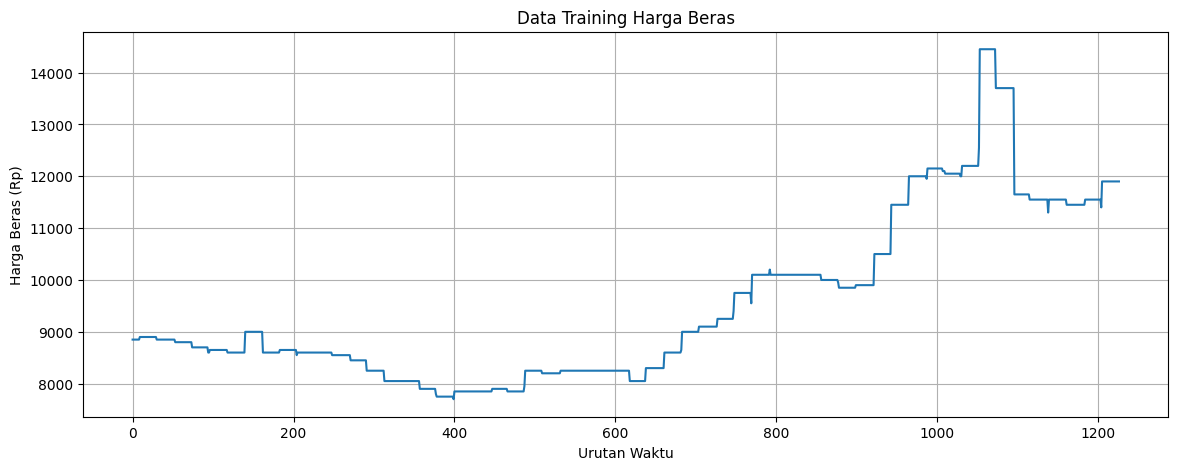

In [7]:
plt.figure(figsize=(14, 5))

plt.plot(train_df['harga_beras'])

plt.title('Data Training Harga Beras')
plt.xlabel('Urutan Waktu')
plt.ylabel('Harga Beras (Rp)')

plt.grid(True)
plt.show()

#Model SARIMAX
Target penelitian ini adalah memprediksi harga komoditas beras. Harga Beras Kualitas Medium I digunakan sebagai fitur tambahan dalam model yang menggunakan feature engineering, tetapi tidak menjadi target kedua dalam penelitian ini.

In [8]:
y_train = train_df['harga_beras']
y_val = val_df['harga_beras']

print("Jumlah data training:", len(y_train))
print("Jumlah data validation:", len(y_val))

Jumlah data training: 1227
Jumlah data validation: 263


# Model Baseline - SARIMAX

In [9]:
model_baseline = SARIMAX(
    y_train,
    order=(1, 1, 1),
    seasonal_order=(0, 0, 0, 0)
)

hasil_baseline = model_baseline.fit()

print(hasil_baseline.summary())

                               SARIMAX Results                                
Dep. Variable:            harga_beras   No. Observations:                 1227
Model:               SARIMAX(1, 1, 1)   Log Likelihood               -7376.096
Date:                Fri, 27 Nov 2026   AIC                          14758.192
Time:                        03:49:37   BIC                          14773.526
Sample:                             0   HQIC                         14763.962
                               - 1227                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0306      7.191     -0.004      0.997     -14.124      14.063
ma.L1          0.0716      7.194      0.010      0.992     -14.028      14.172
sigma2      9878.9921     42.249    233.828      0.0

# Prediksi Data Validation


In [10]:
# Melakukan prediksi pada data validation
prediksi_val = hasil_baseline.forecast(
    steps=len(y_val)
)

print("Hasil prediksi validation:")
print(prediksi_val.head())

Hasil prediksi validation:
1227    11900.0
1228    11900.0
1229    11900.0
1230    11900.0
1231    11900.0
Name: predicted_mean, dtype: float64


# Menghitung MAE, RMSE, dan MAPE
Sesuai dengan rancangan evaluasi model baseline.

In [11]:
mae = mean_absolute_error(y_val, prediksi_val)
rmse = np.sqrt(
    mean_squared_error(y_val, prediksi_val)
)
mape = mean_absolute_percentage_error(
    y_val, prediksi_val
) * 100

print("Hasil Evaluasi Baseline SARIMAX")
print("MAE  :", mae)
print("RMSE :", rmse)
print("MAPE :", mape, "%")

Hasil Evaluasi Baseline SARIMAX
MAE  : 336.88212927756655
RMSE : 478.0744011969768
MAPE : 2.689590931654039 %


# Tabel Hasil Evaluasi

In [12]:
hasil_evaluasi = pd.DataFrame({
    'Model': ['SARIMAX'],
    'MAE': [mae],
    'RMSE': [rmse],
    'MAPE': [mape]
})

display(hasil_evaluasi)

,Model,MAE,RMSE,MAPE
0,SARIMAX,336.882129,478.074401,2.689591


# Grafik aktual dan Prediksi

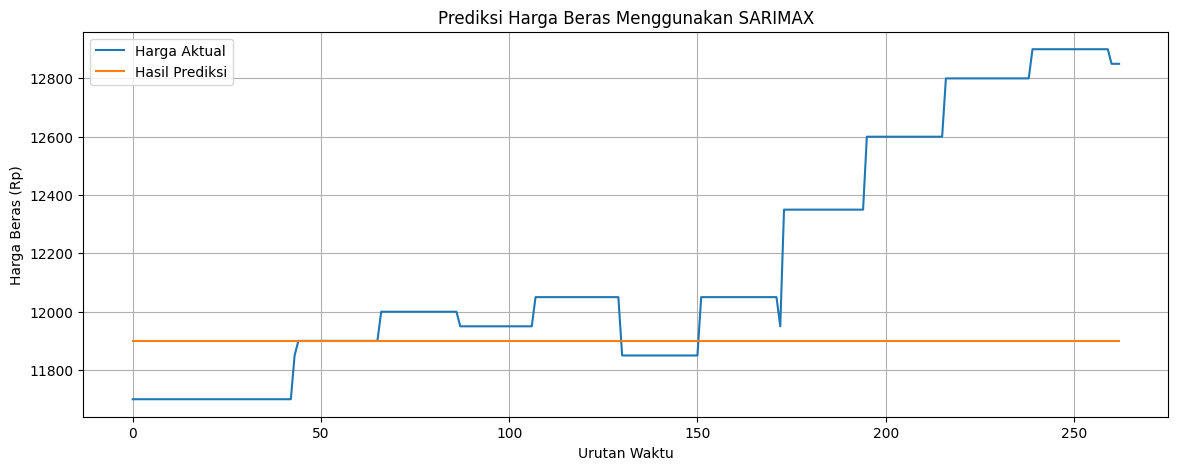

In [13]:
plt.figure(figsize=(14, 5))
plt.plot(
    range(len(y_val)),
    y_val.values,
    label='Harga Aktual'
)
plt.plot(
    range(len(prediksi_val)),
    prediksi_val.values,
    label='Hasil Prediksi'
)

plt.title('Prediksi Harga Beras Menggunakan SARIMAX')
plt.xlabel('Urutan Waktu')
plt.ylabel('Harga Beras (Rp)')

plt.legend()
plt.grid(True)
plt.show()

# Percobaan Beberapa Konfigurasi Parameter

In [14]:
daftar_order = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2)
]

hasil_percobaan = []
for order in daftar_order:
    model = SARIMAX(
        y_train,
        order=order,
        seasonal_order=(0, 0, 0, 0)
    )

    hasil = model.fit()

    prediksi = hasil.forecast(
        steps=len(y_val)
    )

    mae = mean_absolute_error(y_val, prediksi)
    rmse = np.sqrt(
        mean_squared_error(y_val, prediksi)
    )
    mape = mean_absolute_percentage_error(
        y_val, prediksi
    ) * 100

    hasil_percobaan.append({
        'Order': str(order),
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

tabel_percobaan = pd.DataFrame(hasil_percobaan)
display(tabel_percobaan)

,Order,MAE,RMSE,MAPE
0,"(1, 1, 1)",336.882129,478.074401,2.689591
1,"(2, 1, 1)",336.882129,478.074401,2.689591
2,"(1, 1, 2)",336.882129,478.074401,2.689591


# Memastikan Hasil Prediksi Sama atau Tidak

In [15]:
daftar_order = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2)
]

hasil_prediksi = {}

for order in daftar_order:

    model = SARIMAX(
        y_train,
        order=order,
        seasonal_order=(0, 0, 0, 0)
    )

    hasil = model.fit()

    prediksi = hasil.forecast(
        steps=len(y_val)
    )

    hasil_prediksi[str(order)] = prediksi.values
    print("\nOrder:", order)
    print("Parameter model:")
    print(hasil.params)

    print("Lima hasil prediksi pertama:")
    print(prediksi.head().values)


Order: (1, 1, 1)
Parameter model:
ar.L1       -0.030628
ma.L1        0.071615
sigma2    9878.992134
dtype: float64
Lima hasil prediksi pertama:
[11900. 11900. 11900. 11900. 11900.]

Order: (2, 1, 1)
Parameter model:
ar.L1       -0.088343
ar.L2        0.002377
ma.L1        0.129326
sigma2    9878.991510
dtype: float64
Lima hasil prediksi pertama:
[11900. 11900. 11900. 11900. 11900.]

Order: (1, 1, 2)
Parameter model:
ar.L1       -0.161167
ma.L1        0.202117
ma.L2        0.005352
sigma2    9911.426590
dtype: float64
Lima hasil prediksi pertama:
[11900. 11900. 11900. 11900. 11900.]


In [16]:
print(
    "Perbedaan SARIMAX (1,1,1) dan (2,1,1):",
    np.max(np.abs(
        hasil_prediksi['(1, 1, 1)'] -
        hasil_prediksi['(2, 1, 1)']
    ))
)

print(
    "Perbedaan SARIMAX (1,1,1) dan (1,1,2):",
    np.max(np.abs(
        hasil_prediksi['(1, 1, 1)'] -
        hasil_prediksi['(1, 1, 2)']
    ))
)

Perbedaan SARIMAX (1,1,1) dan (2,1,1): 0.0
Perbedaan SARIMAX (1,1,1) dan (1,1,2): 0.0


# Memeriksa Data Training Bagian Akhir

In [17]:
#15 data training terakhir
display(
    train_df[['tanggal', 'harga_beras']].tail(15)
)

,tanggal,harga_beras
1212,2024-10-04,11900.0
1213,2024-10-07,11900.0
1214,2024-10-08,11900.0
1215,2024-10-09,11900.0
1216,2024-10-10,11900.0
1217,2024-10-11,11900.0
1218,2024-10-14,11900.0
1219,2024-10-15,11900.0
1220,2024-10-16,11900.0
1221,2024-10-17,11900.0


In [18]:
#perubahan harga beras
print("Perubahan harga beras pada 15 data terakhir:")

print(
    train_df['harga_beras'].diff().tail(15)
)

Perubahan harga beras pada 15 data terakhir:
1212    0.0
1213    0.0
1214    0.0
1215    0.0
1216    0.0
1217    0.0
1218    0.0
1219    0.0
1220    0.0
1221    0.0
1222    0.0
1223    0.0
1224    0.0
1225    0.0
1226    0.0
Name: harga_beras, dtype: float64


# Pemeriksaan kembali dengan 30 Data Training Terakhir

In [19]:
#memeriksa kembali dengan 30 data training terakhir
display(
    train_df[['tanggal', 'harga_beras']].tail(30)
)

,tanggal,harga_beras
1197,2024-09-13,11550.0
1198,2024-09-16,11550.0
1199,2024-09-17,11550.0
1200,2024-09-18,11550.0
1201,2024-09-19,11550.0
1202,2024-09-20,11550.0
1203,2024-09-23,11550.0
1204,2024-09-24,11400.0
1205,2024-09-25,11900.0
1206,2024-09-26,11900.0


# Jumlah perubahan harga

In [20]:
#jumlah perubahan harga
perubahan_30 = train_df['harga_beras'].tail(30).diff()

print("Jumlah perubahan harga:")
print((perubahan_30 != 0).sum())

print("\nJumlah data dengan perubahan nol:")
print((perubahan_30 == 0).sum())

Jumlah perubahan harga:
3

Jumlah data dengan perubahan nol:
27


# Membuat folder hasil

In [24]:
folder_hasil = folder_proyek + 'results/model_1_sarimax/'
os.makedirs(folder_hasil, exist_ok=True)

# Tabel Hasil Percobaan

In [27]:
tabel_percobaan.to_csv(
    folder_hasil + 'hasil_validasi_sarimax.csv',
    index=False
)

# Model Terbaik

In [30]:
#mengurutkan hasil berdasarkan MAE, RMSE, dan kompleksitas model
tabel_urut = tabel_percobaan.sort_values(
    by=['MAE', 'RMSE'],
    ascending=[True, True]
)

#engambil konfigurasi SARIMAX (1,1,1)
konfigurasi_terbaik = tabel_urut[
    tabel_urut['Order'] == '(1, 1, 1)'
].iloc[0]

print("Konfigurasi SARIMAX terpilih:")
print(konfigurasi_terbaik)

Konfigurasi SARIMAX terpilih:
Order     (1, 1, 1)
MAE      336.882129
RMSE     478.074401
MAPE       2.689591
Name: 0, dtype: object


# Menyimpan Model SARIMAX Terbaik

In [31]:
data_train_val = pd.concat(
    [y_train, y_val],
    ignore_index=True
)

order_terbaik = eval(
    konfigurasi_terbaik['Order']
)

model_terbaik = SARIMAX(
    data_train_val,
    order=order_terbaik,
    seasonal_order=(0, 0, 0, 0)
)

hasil_model_terbaik = model_terbaik.fit()

with open(folder_hasil + 'model_sarimax.pkl', 'wb') as file:
    pickle.dump(hasil_model_terbaik, file)

print("Model SARIMAX berhasil disimpan.")

Model SARIMAX berhasil disimpan.
